In [101]:

import pandas as pd

df = pd.read_csv("/content/Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (250, 7)


,Unnamed: 0,Fruit,Temp,Humidity,CO2,Days,Spoiled
0,107,Banana,18,58,410,5,No
1,1,Banana,22,55,399,6,Yes
2,44,Plum,23,68,399,4,Yes
3,67,Tomato,22,55,419,6,Yes
4,45,Plum,22,53,400,5,Yes


In [102]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()


Column names:
['Unnamed: 0', 'Fruit', 'Temp', 'Humidity', 'CO2', 'Days', 'Spoiled']

Missing values:
Unnamed: 0    0
Fruit         0
Temp          0
Humidity      0
CO2           0
Days          0
Spoiled       0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  250 non-null    int64 
 1   Fruit       250 non-null    object
 2   Temp        250 non-null    int64 
 3   Humidity    250 non-null    int64 
 4   CO2         250 non-null    int64 
 5   Days        250 non-null    int64 
 6   Spoiled     250 non-null    object
dtypes: int64(5), object(2)
memory usage: 13.8+ KB


In [103]:

# 1. Remove the unnecessary index column
df = df.drop(columns=["Unnamed: 0"])

# 2. Remove duplicate rows
df = df.drop_duplicates()

# 3. Remove extra spaces from text values
df["Fruit"] = df["Fruit"].str.strip()
df["Spoiled"] = df["Spoiled"].str.strip().str.title()

# 4. Check for missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())
print("\nCleaned dataset shape:", df.shape)

display(df.head())



Missing values after cleaning:
Fruit       0
Temp        0
Humidity    0
CO2         0
Days        0
Spoiled     0
dtype: int64

Duplicate rows after cleaning: 0

Cleaned dataset shape: (244, 6)


,Fruit,Temp,Humidity,CO2,Days,Spoiled
0,Banana,18,58,410,5,No
1,Banana,22,55,399,6,Yes
2,Plum,23,68,399,4,Yes
3,Tomato,22,55,419,6,Yes
4,Plum,22,53,400,5,Yes


In [104]:

print("Fruit types:")
print(df["Fruit"].unique())

print("\nSpoilage labels:")
print(df["Spoiled"].value_counts())

print("\nData types:")
print(df.dtypes)


Fruit types:
['Banana' 'Plum' 'Tomato' 'Jackfruit' 'Grapes' 'Lemon' 'Mango' 'Papaya'
 'Litchi' 'Apple']

Spoilage labels:
Spoiled
No     144
Yes    100
Name: count, dtype: int64

Data types:
Fruit       object
Temp         int64
Humidity     int64
CO2          int64
Days         int64
Spoiled     object
dtype: object


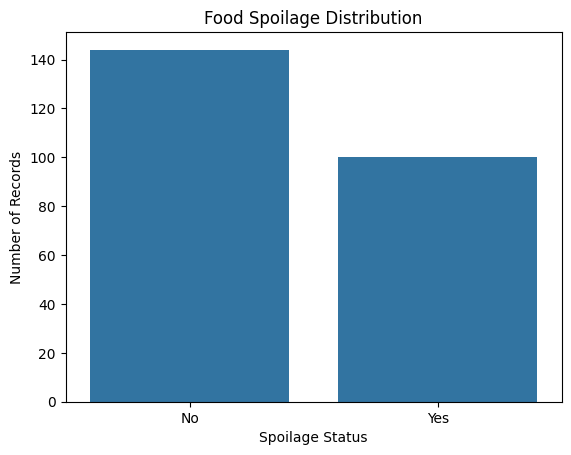

In [105]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Spoiled")
plt.title("Food Spoilage Distribution")
plt.xlabel("Spoilage Status")
plt.ylabel("Number of Records")
plt.show()


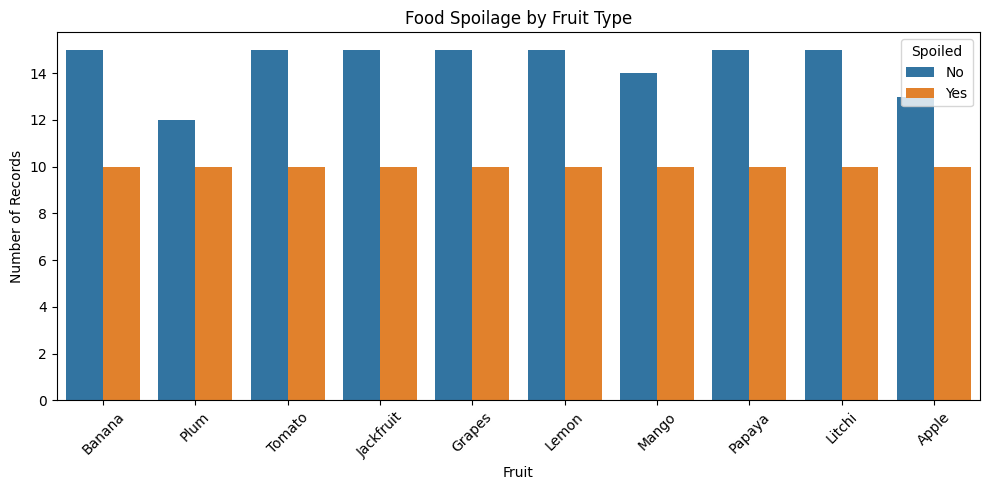

In [106]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Fruit", hue="Spoiled")
plt.title("Food Spoilage by Fruit Type")
plt.xlabel("Fruit")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [107]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)
from sklearn.base import clone
import pandas as pd

# Input features and target
X = df.drop(columns=["Spoiled"])
y = df["Spoiled"]

categorical_cols = ["Fruit"]
numeric_cols = ["Temp", "Humidity", "CO2", "Days"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Preprocessing for Decision Tree and Random Forest
tree_preprocessor = ColumnTransformer([
    ("fruit", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("numbers", "passthrough", numeric_cols)
])

# Preprocessing for SVM (scaling numerical values)
svm_preprocessor = ColumnTransformer([
    ("fruit", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("numbers", StandardScaler(), numeric_cols)
])

models = {
    "Decision Tree": Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("model", DecisionTreeClassifier(
            random_state=42, class_weight="balanced"
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=100, random_state=42,
            class_weight="balanced"
        ))
    ]),
    "SVM": Pipeline([
        ("prep", clone(svm_preprocessor)),
        ("model", SVC(
            kernel="rbf", class_weight="balanced"
        ))
    ])
}

results = []
trained_models = {}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    trained_models[name] = clf

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test, pred, pos_label="Yes",
                            zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, pred, pos_label="Yes",
                         zero_division=0) * 100, 2
        ),
        "F1-score (%)": round(
            f1_score(y_test, pred, pos_label="Yes",
                     zero_division=0) * 100, 2
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (%)", ascending=False
)

display(results_df)


,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Decision Tree,75.51,68.18,75.0,71.43
2,SVM,53.06,44.44,60.0,51.06
1,Random Forest,55.10,43.75,35.0,38.89


In [108]:

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model by test F1-score:", best_name)
print("\nDetailed classification report:")
print(
    classification_report(
        y_test,
        best_model.predict(X_test),
        zero_division=0
    )
)


Best model by test F1-score: Decision Tree

Detailed classification report:
              precision    recall  f1-score   support

          No       0.81      0.76      0.79        29
         Yes       0.68      0.75      0.71        20

    accuracy                           0.76        49
   macro avg       0.75      0.75      0.75        49
weighted avg       0.76      0.76      0.76        49



In [109]:

import gradio as gr
import pandas as pd

# Select the best model from your comparison
best_model = trained_models["Decision Tree"]

def predict_spoilage(fruit, temp, humidity, co2, days):
    sample = pd.DataFrame([{
        "Fruit": fruit,
        "Temp": temp,
        "Humidity": humidity,
        "CO2": co2,
        "Days": days
    }])

    prediction = best_model.predict(sample)[0]

    if prediction == "Yes":
        result = "⚠️ Spoilage predicted"
    else:
        result = "✅ Spoilage not predicted"

    return (
        f"{result}\n\n"
        f"Fruit: {fruit}\n"
        f"Temperature: {temp} °C\n"
        f"Humidity: {humidity}%\n"
        f"CO2: {co2} ppm\n"
        f"Storage duration: {days} days\n\n"
        "Note: This is an ML estimate, not a food-safety test."
    )

fruit_choices = sorted(df["Fruit"].unique().tolist())

demo = gr.Interface(
    fn=predict_spoilage,
    inputs=[
        gr.Dropdown(fruit_choices, label="Select Fruit"),
        gr.Number(value=22, label="Temperature (°C)"),
        gr.Number(value=60, label="Humidity (%)"),
        gr.Number(value=410, label="CO2 concentration (ppm)"),
        gr.Number(value=4, label="Storage duration (days)")
    ],
    outputs=gr.Textbox(label="FreshGuard Prediction"),
    title="FreshGuard — Food Spoilage Prediction",
    description="Enter storage conditions to predict the spoilage category."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e895018f1d4ccf8135.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [110]:

!pip -q install gradio


In [111]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e895018f1d4ccf8135.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [112]:

import gradio as gr
import pandas as pd

best_model = trained_models["Decision Tree"]

def predict_spoilage(fruit, temp, humidity, co2, days):
    sample = pd.DataFrame([{
        "Fruit": fruit,
        "Temp": temp,
        "Humidity": humidity,
        "CO2": co2,
        "Days": days
    }])

    prediction = best_model.predict(sample)[0]

    if prediction == "Yes":
        result = "Spoilage predicted"
    else:
        result = "Spoilage not predicted"

    return result

demo = gr.Interface(
    fn=predict_spoilage,
    inputs=[
        gr.Dropdown(
            choices=sorted(df["Fruit"].unique().tolist()),
            label="Fruit Type"
        ),
        gr.Number(value=22, label="Temperature (°C)"),
        gr.Number(value=60, label="Humidity (%)"),
        gr.Number(value=410, label="CO2 (ppm)"),
        gr.Number(value=4, label="Storage Days")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="FreshGuard - Food Spoilage Prediction",
    description="Enter the storage conditions to predict food spoilage."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5635cdcbb098d75ca9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [113]:

import joblib

best_model = trained_models["Decision Tree"]

joblib.dump(best_model, "freshguard_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [114]:

from google.colab import files

files.download("freshguard_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>